Transformações nos dados, para multiplicar os dados de treino artificialmente e traduzir as imagens para algo que o modelo entende

In [3]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# compose para o treino
transform_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# compose para o teste
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Lendo as pastas e criando os rotulos

train_dataset = datasets.ImageFolder(root='../data/split/train', transform=transform_train)
test_dataset = datasets.ImageFolder(root='../data/split/test', transform=transform_test)

# Criando os dataloaders

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)

# testes

print(train_dataset.classes)
print(train_dataset.class_to_idx)
print(len(train_dataset))
print(len(test_dataset))

['monster', 'nao_monster']
{'monster': 0, 'nao_monster': 1}
44
12


Carregando o modelo

In [5]:
import torch.nn as nn
import torch.optim as optim
from torchvision import models

modelo_pretreinado = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# congelando os pesos do modelo pré-treinado

for param in modelo_pretreinado.parameters():
    param.requires_grad = False

# substituindo a camada final para o número de classes do nosso dataset
num_classes = len(train_dataset.classes)
modelo_pretreinado.fc = nn.Linear(modelo_pretreinado.fc.in_features, num_classes)

# função de perda e otimizador
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(modelo_pretreinado.fc.parameters(), lr=0.001)

# verificando se o modelo esta certo

print(modelo_pretreinado.fc)

Linear(in_features=512, out_features=2, bias=True)


Treinamento do Modelo

In [ ]:
num_epochs = 50

for epoch in range(num_epochs):
    modelo_pretreinado.train()
    loss_total = 0.0
    for imagens, rotulos in train_loader:
        optimizer.zero_grad()
        saidas = modelo_pretreinado(imagens)
        loss = criterion(saidas, rotulos)
        loss.backward()
        optimizer.step()
        loss_total += loss.item()
    loss_medio = loss_total / len(train_loader)
    print(f'Época [{epoch+1}/{num_epochs}], Loss: {loss_medio:.4f}')

Época [1/40], Loss: 0.6228
Época [2/40], Loss: 0.5542
Época [3/40], Loss: 0.4122
Época [4/40], Loss: 0.4252
Época [5/40], Loss: 0.3935
Época [6/40], Loss: 0.4320
Época [7/40], Loss: 0.3546
Época [8/40], Loss: 0.3466
Época [9/40], Loss: 0.3642
Época [10/40], Loss: 0.3345
Época [11/40], Loss: 0.3594
Época [12/40], Loss: 0.3453
Época [13/40], Loss: 0.3751
Época [14/40], Loss: 0.3180
Época [15/40], Loss: 0.2669
Época [16/40], Loss: 0.2697
Época [17/40], Loss: 0.3644
Época [18/40], Loss: 0.2960
Época [19/40], Loss: 0.3177
Época [20/40], Loss: 0.2522
Época [21/40], Loss: 0.3513
Época [22/40], Loss: 0.3210
Época [23/40], Loss: 0.3054
Época [24/40], Loss: 0.3461
Época [25/40], Loss: 0.2797
Época [26/40], Loss: 0.3740
Época [27/40], Loss: 0.2546
Época [28/40], Loss: 0.2951
Época [29/40], Loss: 0.2415
Época [30/40], Loss: 0.2111
Época [31/40], Loss: 0.1874
Época [32/40], Loss: 0.2788
Época [33/40], Loss: 0.3000
Época [34/40], Loss: 0.2395
Época [35/40], Loss: 0.2463
Época [36/40], Loss: 0.2036
É

Avaliação do modelo

In [8]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

modelo_pretreinado.eval()
y_true = []
y_pred = []

with torch.no_grad():
    for imagens, rotulos in test_loader:
        saidas = modelo_pretreinado(imagens)
        _, predicoes = torch.max(saidas, 1)
        y_true.extend(rotulos.numpy())
        y_pred.extend(predicoes.numpy())


print(accuracy_score(y_true, y_pred))
print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred))


0.8333333333333334
[[5 0]
 [2 5]]
              precision    recall  f1-score   support

           0       0.71      1.00      0.83         5
           1       1.00      0.71      0.83         7

    accuracy                           0.83        12
   macro avg       0.86      0.86      0.83        12
weighted avg       0.88      0.83      0.83        12



Análise dos erros e Grad-CAM

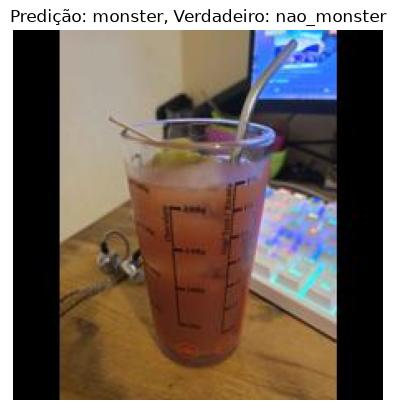

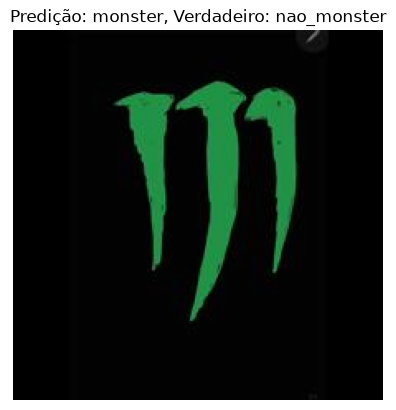

In [10]:
import matplotlib.pyplot as plt
from PIL import Image

for idx, (pred, true) in enumerate(zip(y_pred, y_true)):
    if pred != true:
        imagem = test_dataset[idx][0]
        imagem = imagem.permute(1, 2, 0).numpy()
        imagem = ((imagem * [0.229, 0.224, 0.225]) + [0.485, 0.456, 0.406]).clip(0, 1)  # Desnormalizando
        plt.imshow(imagem)
        plt.title(f'Predição: {train_dataset.classes[pred]}, Verdadeiro: {train_dataset.classes[true]}')
        plt.axis('off')
        plt.show()

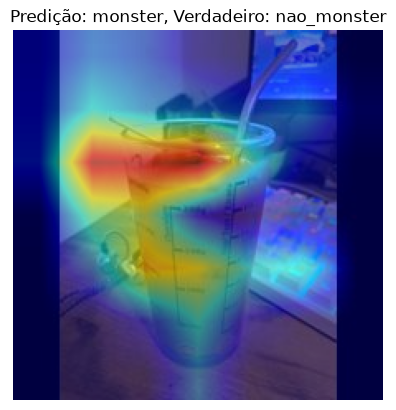

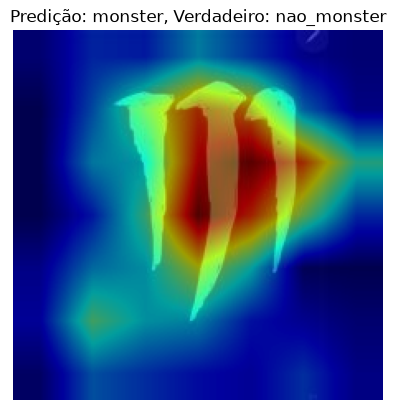

In [12]:
import numpy as np
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

for params in modelo_pretreinado.layer4.parameters():
    params.requires_grad = True  # Descongelando a última camada para o Grad-CAM

target_layers = [modelo_pretreinado.layer4[-1]]  # Última camada convolucional do ResNet18
cam = GradCAM(model=modelo_pretreinado, target_layers=target_layers)

for idx, (pred, true) in enumerate(zip(y_pred, y_true)):
    if pred != true:
        input_tensor = test_dataset[idx][0].unsqueeze(0)  # Adicionando dimensão de batch
        grayscale_cam = cam(input_tensor=input_tensor, targets=None)[0]
        imagem = test_dataset[idx][0].permute(1, 2, 0).numpy()
        imagem = ((imagem * [0.229, 0.224, 0.225]) + [0.485, 0.456, 0.406]).clip(0, 1)  # Desnormalizando
        visualization = show_cam_on_image(imagem, grayscale_cam, use_rgb=True)
        plt.imshow(visualization)
        plt.title(f'Predição: {train_dataset.classes[pred]}, Verdadeiro: {train_dataset.classes[true]}')
        plt.axis('off')
        plt.show() 


